# Q1 — Data preparation, leakage and experimental design (Telco Customer Churn)

Sections: **Q1a** data audit · Q1b split comparison · Q1c preprocessing · Q1d leakage demo · Q1e audit table and failure modes.

**Protocol note.** Descriptive data-quality checks in Q1a (types, missing values, duplicates, ranges, category levels) fit nothing and are computed on the full data. Any analysis that involves the **target** and could influence modelling decisions (churn rate by feature) is computed on the **training split only**. The test split is never inspected.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'utils.py').exists())
sys.path.insert(0, str(ROOT))

from src.utils import *
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

set_seed()
pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid')

raw = load_telco_raw()                # exactly as in the CSV
X, y, ids = load_telco()              # TotalCharges -> float, SeniorCitizen -> No/Yes, y -> 0/1
parts = load_split(X, y, CLF_SPLIT_FILE, ids=ids)
X_train, y_train = parts['X_train'], parts['y_train']
split_labels = pd.read_csv(CLF_SPLIT_FILE)['split']

print('raw:', raw.shape, '| X:', X.shape, '| train:', X_train.shape)

raw: (7043, 21) | X: (7043, 19) | train: (4225, 19)


## Q1a.1 — Overview: columns, types, roles

In [2]:
roles = {TELCO_ID: 'ID (not a feature)', TELCO_TARGET: 'target'}
roles.update({c: 'numeric' for c in NUM_COLS})
roles.update({c: 'categorical' for c in CAT_COLS})

types = pd.DataFrame({
    'column': raw.columns,
    'raw_dtype': [str(raw[c].dtype) for c in raw.columns],
    'role': [roles[c] for c in raw.columns],
    'n_unique': [raw[c].nunique() for c in raw.columns],
})
save_table(types, 'q1a_feature_types')
print(f'{raw.shape[0]} rows, {raw.shape[1]} columns -> '
      f'{len(NUM_COLS)} numeric + {len(CAT_COLS)} categorical features, 1 ID, 1 target')
types

7043 rows, 21 columns -> 3 numeric + 16 categorical features, 1 ID, 1 target


,column,raw_dtype,role,n_unique
0,customerID,str,ID (not a feature),7043
1,gender,str,categorical,2
2,SeniorCitizen,int64,categorical,2
3,Partner,str,categorical,2
4,Dependents,str,categorical,2
5,tenure,int64,numeric,73
6,PhoneService,str,categorical,2
7,MultipleLines,str,categorical,3
8,InternetService,str,categorical,3
9,OnlineSecurity,str,categorical,3


## Q1a.2 — Class distribution

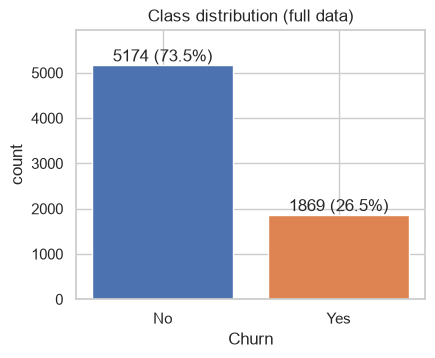

,Churn,count,fraction
0,No,5174,0.73463
1,Yes,1869,0.26537


In [3]:
cls = raw[TELCO_TARGET].value_counts().rename_axis('Churn').reset_index(name='count')
cls['fraction'] = cls['count'] / cls['count'].sum()
save_table(cls, 'q1a_class_distribution')

fig, ax = plt.subplots(figsize=(4.5, 3.5))
ax.bar(cls['Churn'], cls['count'], color=['#4C72B0', '#DD8452'])
for i, r in cls.iterrows():
    ax.text(i, r['count'], f"{r['count']} ({r['fraction']:.1%})", ha='center', va='bottom')
ax.set_ylim(0, cls['count'].max() * 1.15)
ax.set_xlabel('Churn'); ax.set_ylabel('count')
ax.set_title('Class distribution (full data)')
save_fig(fig, 'q1a_class_distribution'); plt.show()
cls

## Q1a.3 — Missing values

`TotalCharges` is stored as text in the CSV; missing entries appear as blank strings, not as NaN, so both are counted.

In [4]:
missing = pd.DataFrame({
    'NaN': raw.isna().sum(),
    'blank_string': raw.apply(lambda s: s.astype(str).str.strip().eq('').sum()),
})
missing = missing[missing.sum(axis=1) > 0]
print('Columns with NaN or blank strings:')
display(missing)

blank_mask = raw['TotalCharges'].astype(str).str.strip().eq('')
blank_rows = raw.loc[blank_mask, [TELCO_ID, 'tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', TELCO_TARGET]]
blank_rows = blank_rows.assign(split=split_labels[blank_mask].to_numpy())
save_table(blank_rows, 'q1a_blank_totalcharges')
print(f'{blank_mask.sum()} rows with blank TotalCharges '
      f'({blank_mask.mean():.3%} of the data). After load_telco() they are NaN: {X["TotalCharges"].isna().sum()}')
blank_rows

Columns with NaN or blank strings:


,NaN,blank_string
TotalCharges,0,11


11 rows with blank TotalCharges (0.156% of the data). After load_telco() they are NaN: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn,split
488,4472-LVYGI,0,52.55,,Two year,No,train
753,3115-CZMZD,0,20.25,,Two year,No,train
936,5709-LVOEQ,0,80.85,,Two year,No,train
1082,4367-NUYAO,0,25.75,,Two year,No,val
1340,1371-DWPAZ,0,56.05,,Two year,No,train
3331,7644-OMVMY,0,19.85,,Two year,No,train
3826,3213-VVOLG,0,25.35,,Two year,No,train
4380,2520-SGTTA,0,20.00,,Two year,No,train
5218,2923-ARZLG,0,19.70,,One year,No,train
6670,4075-WKNIU,0,73.35,,Two year,No,train


## Q1a.4 — Duplicates (with and without `customerID`)

Also checked: whether feature-identical rows carry **different** churn labels, and whether duplicate groups are **spread across splits** (a potential leakage route between train and val/test).

In [5]:
feat_cols = NUM_COLS + CAT_COLS
no_id = raw.drop(columns=TELCO_ID)
feat_dup_mask = raw[feat_cols].duplicated(keep=False)

dup_groups = raw.loc[feat_dup_mask, feat_cols + [TELCO_TARGET]].assign(split=split_labels[feat_dup_mask].to_numpy())
group_key = dup_groups[feat_cols].astype(str).agg('|'.join, axis=1)
per_group = dup_groups.groupby(group_key).agg(size=(TELCO_TARGET, 'size'),
                                              n_labels=(TELCO_TARGET, 'nunique'),
                                              n_splits=('split', 'nunique'))

dups = pd.DataFrame([
    ('identical rows incl. customerID (extra copies)', raw.duplicated().sum()),
    ('duplicated customerID values', raw[TELCO_ID].duplicated().sum()),
    ('identical rows excl. customerID, features+target (extra copies)', no_id.duplicated().sum()),
    ('identical rows excl. customerID, features only (extra copies)', raw[feat_cols].duplicated().sum()),
    ('rows belonging to a feature-duplicate group', feat_dup_mask.sum()),
    ('feature-duplicate groups', len(per_group)),
    ('groups with conflicting Churn labels', int((per_group['n_labels'] > 1).sum())),
    ('groups spread over more than one split', int((per_group['n_splits'] > 1).sum())),
], columns=['check', 'count'])
save_table(dups, 'q1a_duplicates')
display(dups)

print('Largest duplicate groups (feature columns identical):')
display(per_group.sort_values('size', ascending=False).head(5))
print('Example rows from duplicate groups:')
raw.loc[feat_dup_mask].sort_values(feat_cols).head(8)

,check,count
0,identical rows incl. customerID (extra copies),0
1,duplicated customerID values,0
2,"identical rows excl. customerID, features+targ...",22
3,"identical rows excl. customerID, features only...",40
4,rows belonging to a feature-duplicate group,73
5,feature-duplicate groups,33
6,groups with conflicting Churn labels,18
7,groups spread over more than one split,21


Largest duplicate groups (feature columns identical):


,size,n_labels,n_splits
1|20.2|20.2|Male|0|No|No|Yes|No|No|No internet service|No internet service|No internet service|No internet service|No internet service|No internet service|Month-to-month|No|Mailed check,4,2,2
1|69.9|69.9|Male|0|No|No|Yes|No|Fiber optic|No|No|No|No|No|No|Month-to-month|Yes|Electronic check,3,2,2
1|19.65|19.65|Female|0|No|No|Yes|No|No|No internet service|No internet service|No internet service|No internet service|No internet service|No internet service|Month-to-month|No|Mailed check,3,2,3
1|20.05|20.05|Male|0|No|No|Yes|No|No|No internet service|No internet service|No internet service|No internet service|No internet service|No internet service|Month-to-month|No|Mailed check,3,1,2
1|19.9|19.9|Female|0|No|No|Yes|No|No|No internet service|No internet service|No internet service|No internet service|No internet service|No internet service|Month-to-month|No|Mailed check,3,2,3


Example rows from duplicate groups:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
1736,7551-JOHTI,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.50,19.5,Yes
4172,1905-OEILC,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.50,19.5,No
542,2866-IKBTM,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.55,19.55,No
1491,8605-ITULD,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.55,19.55,No
710,1029-QFBEN,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.55,19.55,Yes
6449,7601-WFVZV,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.55,19.55,No
1049,8329-IBCTI,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.65,19.65,Yes
5170,7721-DVEKZ,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.65,19.65,No


## Q1a.5 — Numeric ranges and anomalous values

,count,mean,std,min,25%,50%,75%,max,skew,n_zero,n_negative
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00,0.239540,11,0
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75,-0.220524,0,0
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80,0.961642,0,0


rows with tenure == 0              : 11
  of which TotalCharges is NaN     : 11
TotalCharges NaN with tenure > 0   : 0


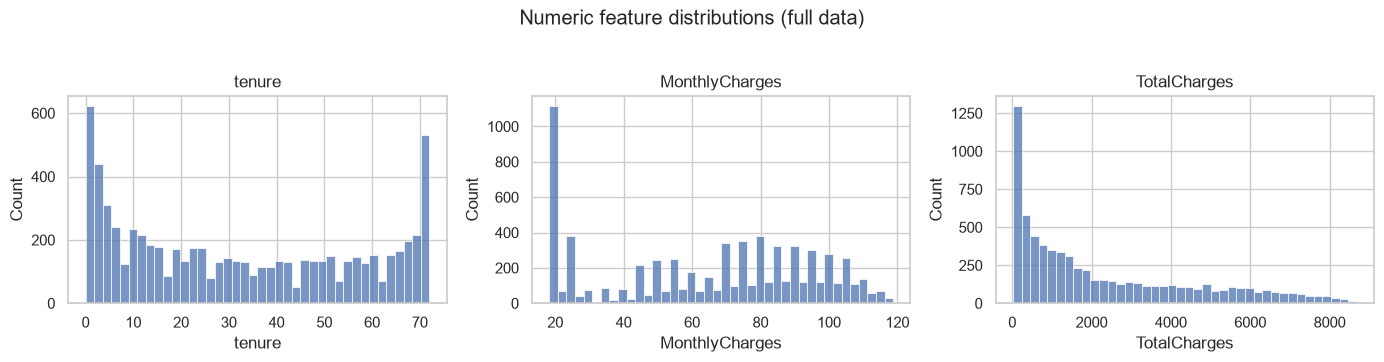

In [6]:
num = X[NUM_COLS]
summary = num.describe().T
summary['skew'] = num.skew()
summary['n_zero'] = (num == 0).sum()
summary['n_negative'] = (num < 0).sum()
save_table(summary.reset_index(names='feature'), 'q1a_numeric_summary')
display(summary)

t0 = X['tenure'] == 0
print('rows with tenure == 0              :', t0.sum())
print('  of which TotalCharges is NaN     :', X.loc[t0, 'TotalCharges'].isna().sum())
print('TotalCharges NaN with tenure > 0   :', X.loc[~t0, 'TotalCharges'].isna().sum())

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, c in zip(axes, NUM_COLS):
    sns.histplot(num[c].dropna(), bins=40, ax=ax)
    ax.set_title(c)
fig.suptitle('Numeric feature distributions (full data)', y=1.03)
fig.tight_layout()
save_fig(fig, 'q1a_numeric_distributions'); plt.show()

## Q1a.6 — Redundancy: `TotalCharges` vs `tenure × MonthlyCharges`

Pearson:


,tenure,MonthlyCharges,TotalCharges,tenure_x_monthly
tenure,1.000,0.248,0.826,0.827
MonthlyCharges,0.248,1.000,0.651,0.652
TotalCharges,0.826,0.651,1.000,1.000
tenure_x_monthly,0.827,0.652,1.000,1.000


Spearman:


,tenure,MonthlyCharges,TotalCharges,tenure_x_monthly
tenure,1.000,0.276,0.889,0.890
MonthlyCharges,0.276,1.000,0.638,0.638
TotalCharges,0.889,0.638,1.000,1.000
tenure_x_monthly,0.890,0.638,1.000,1.000


Relative difference (TotalCharges - tenure*MonthlyCharges) / (tenure*MonthlyCharges):


,count,mean,std,min,25%,50%,75%,max
rel_diff,7032.0,0.000275,0.051159,-0.310644,-0.020454,0.0,0.019562,0.573454


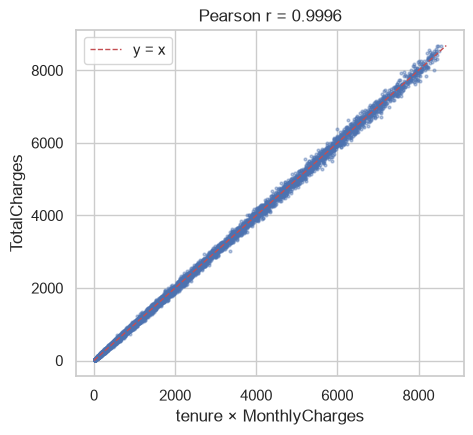

In [7]:
num_ext = num.assign(tenure_x_monthly=X['tenure'] * X['MonthlyCharges'])
corr_p = num_ext.corr(method='pearson')
corr_s = num_ext.corr(method='spearman')
save_table(corr_p.reset_index(names='feature'), 'q1a_numeric_corr_pearson')
save_table(corr_s.reset_index(names='feature'), 'q1a_numeric_corr_spearman')
print('Pearson:');  display(corr_p.round(3))
print('Spearman:'); display(corr_s.round(3))

rel_diff = ((X['TotalCharges'] - num_ext['tenure_x_monthly']) / num_ext['tenure_x_monthly']).dropna()
print('Relative difference (TotalCharges - tenure*MonthlyCharges) / (tenure*MonthlyCharges):')
display(rel_diff.describe().to_frame('rel_diff').T)

fig, ax = plt.subplots(figsize=(5, 4.5))
ax.scatter(num_ext['tenure_x_monthly'], X['TotalCharges'], s=4, alpha=0.4)
lim = [0, np.nanmax(num_ext.values)]
ax.plot(lim, lim, 'r--', lw=1, label='y = x')
ax.set_xlabel('tenure × MonthlyCharges'); ax.set_ylabel('TotalCharges')
ax.set_title(f"Pearson r = {corr_p.loc['TotalCharges', 'tenure_x_monthly']:.4f}")
ax.legend()
save_fig(fig, 'q1a_totalcharges_scatter'); plt.show()

## Q1a.7 — Categorical levels: rare and dependent categories

In [8]:
rows = []
for c in CAT_COLS:
    for lvl, n in X[c].value_counts().items():
        rows.append({'feature': c, 'level': lvl, 'count': n, 'fraction': n / len(X)})
levels = pd.DataFrame(rows)
levels['rare_lt_5pct'] = levels['fraction'] < 0.05
save_table(levels, 'q1a_category_levels')
print('Rare levels (< 5% of rows):')
display(levels[levels['rare_lt_5pct']])

# Structurally dependent levels: a level that is fully determined by another column
services = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
            'TechSupport', 'StreamingTV', 'StreamingMovies']
checks = [(s, 'No internet service', 'InternetService', 'No') for s in services]
checks.append(('MultipleLines', 'No phone service', 'PhoneService', 'No'))
dep = pd.DataFrame([{
    'feature': f, 'level': lvl, 'determined_by': f'{parent} == {pval}',
    'rows_with_level': int((X[f] == lvl).sum()),
    'rows_with_condition': int((X[parent] == pval).sum()),
    'identical_rows': bool(((X[f] == lvl) == (X[parent] == pval)).all()),
} for f, lvl, parent, pval in checks])
save_table(dep, 'q1a_dependent_categories')
print('Dependent levels:')
display(dep)

print('Example cross-tab (InternetService x OnlineSecurity):')
pd.crosstab(X['InternetService'], X['OnlineSecurity'])

Rare levels (< 5% of rows):


,feature,level,count,fraction,rare_lt_5pct


Dependent levels:


,feature,level,determined_by,rows_with_level,rows_with_condition,identical_rows
0,OnlineSecurity,No internet service,InternetService == No,1526,1526,True
1,OnlineBackup,No internet service,InternetService == No,1526,1526,True
2,DeviceProtection,No internet service,InternetService == No,1526,1526,True
3,TechSupport,No internet service,InternetService == No,1526,1526,True
4,StreamingTV,No internet service,InternetService == No,1526,1526,True
5,StreamingMovies,No internet service,InternetService == No,1526,1526,True
6,MultipleLines,No phone service,PhoneService == No,682,682,True


Example cross-tab (InternetService x OnlineSecurity):


OnlineSecurity,No,No internet service,Yes
InternetService,,,
DSL,1241,0,1180
Fiber optic,2257,0,839
No,0,1526,0


## Q1a.8 — Univariate relation to the target (TRAIN split only)

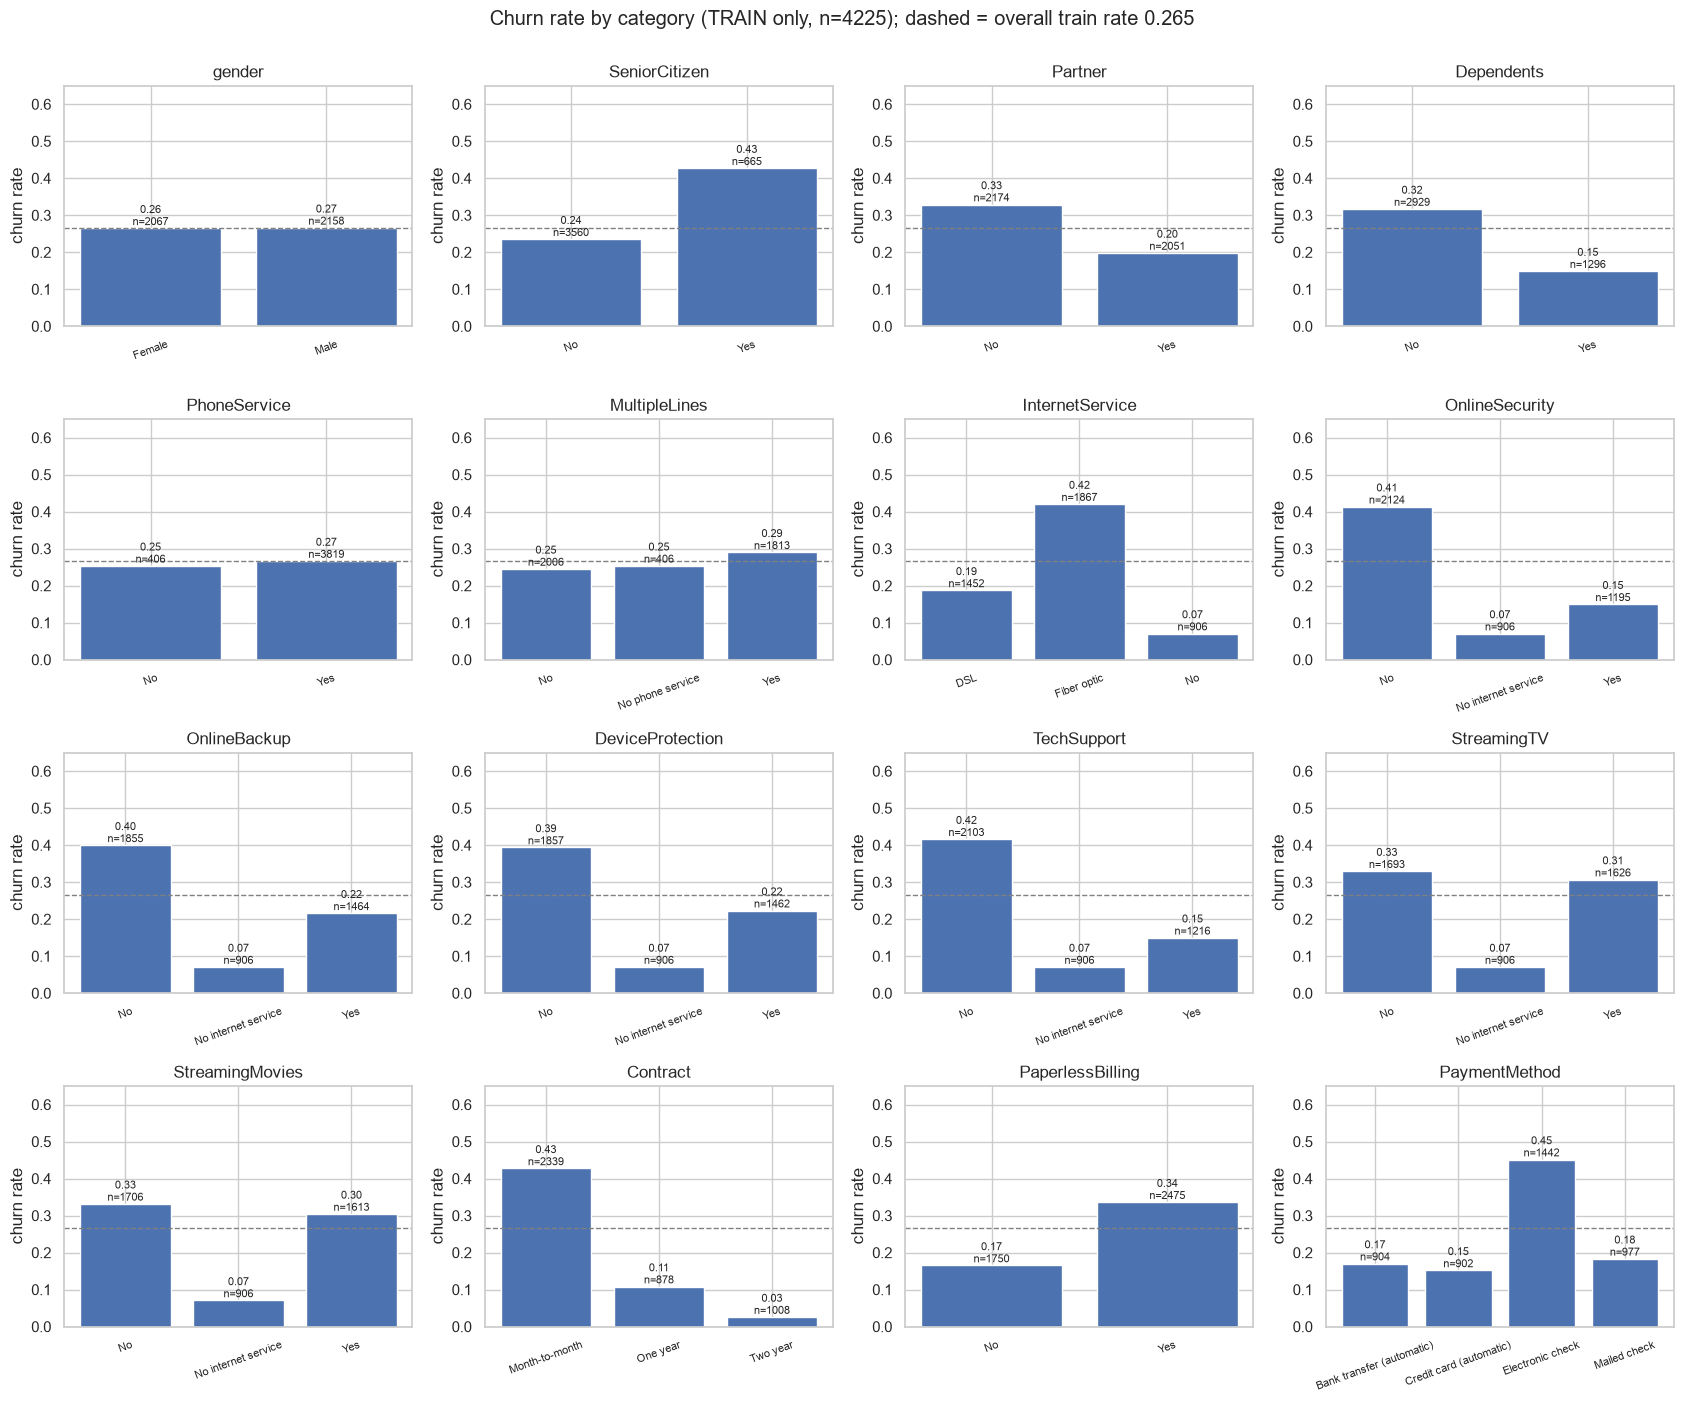

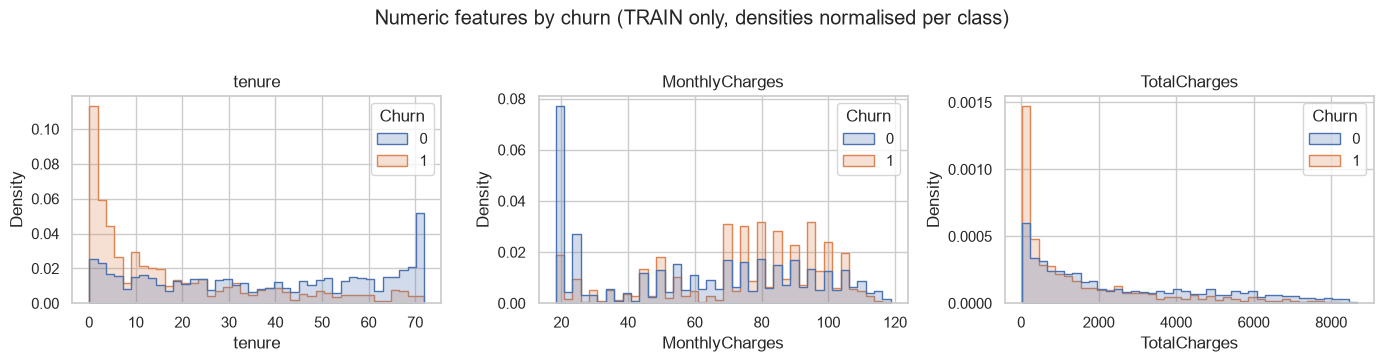

In [9]:
train = X_train.assign(Churn=y_train)
base_rate = y_train.mean()

rate_rows = []
fig, axes = plt.subplots(4, 4, figsize=(17, 14))
for ax, c in zip(axes.ravel(), CAT_COLS):
    g = train.groupby(c)['Churn'].agg(['mean', 'size'])
    ax.bar(g.index.astype(str), g['mean'], color='#4C72B0')
    for i, (m, n) in enumerate(zip(g['mean'], g['size'])):
        ax.text(i, m, f'{m:.2f}\nn={n}', ha='center', va='bottom', fontsize=8)
    ax.axhline(base_rate, ls='--', color='gray', lw=1)
    ax.set_ylim(0, 0.65); ax.set_title(c); ax.set_ylabel('churn rate')
    ax.tick_params(axis='x', labelrotation=20, labelsize=8)
    rate_rows += [{'feature': c, 'level': lvl, 'n_train': int(n), 'churn_rate': m}
                  for lvl, m, n in zip(g.index, g['mean'], g['size'])]
fig.suptitle(f'Churn rate by category (TRAIN only, n={len(train)}); dashed = overall train rate {base_rate:.3f}', y=1.0)
fig.tight_layout()
save_fig(fig, 'q1a_churn_rate_by_category'); plt.show()

rates = pd.DataFrame(rate_rows)
save_table(rates, 'q1a_churn_rate_by_category_train')

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, c in zip(axes, NUM_COLS):
    sns.histplot(data=train, x=c, hue='Churn', bins=40, stat='density',
                 common_norm=False, element='step', ax=ax)
    ax.set_title(c)
fig.suptitle('Numeric features by churn (TRAIN only, densities normalised per class)', y=1.03)
fig.tight_layout()
save_fig(fig, 'q1a_numeric_by_churn_train'); plt.show()

## Q1a — Points for **you** to interpret in the report

*(Answer these from the outputs above in your own words; Claude does not write this text.)*

1. **Imbalance:** What is the exact class ratio? Which metric problems does it imply (accuracy of a majority-class baseline)?
2. **Missing values:** How many, in which column, and what do the affected rows have in common (`tenure`, `Contract`)? Are they truly *unknown* or *structurally* missing? Does median imputation make sense for them?
3. **Duplicates:** Are there duplicates with `customerID`? Without it? Do they have conflicting labels? Are they likely real distinct customers with identical profiles or data errors? Do duplicate groups cross splits, and does that matter?
4. **Anomalies:** Any impossible / out-of-range values? What about `tenure == 0`, skewness of `TotalCharges`?
5. **Redundancy:** How close is `TotalCharges` to `tenure × MonthlyCharges`? What does that mean for linear models (collinearity), NB (independence assumption) and importance analysis (Q4e)?
6. **Problematic predictors:** `customerID` (why it must be removed), rare levels, and the structurally dependent `No internet service` / `No phone service` levels (what one-hot encoding does with them).
7. **Target relations (train only):** Which features show the strongest univariate differences in churn rate? (Description only; these are not causal claims.)

---
# Q1b — Train/validation/test split: stratified vs random

### Q1b.1 — Exact sizes of the fixed split (created once in `00_setup_split.ipynb`)

Test 20% is separated first, the remaining 80% is split 75/25 into train/val → 60/20/20 of the data, stratified on `Churn`, `random_state = 463`.

In [ ]:
clf_sizes = pd.read_csv(TABLES_DIR / 'clf_split_sizes.csv')   # produced by notebook 00 (fixed split)
clf_sizes

### Q1b.2 — Stratified vs random: 200 seeds

For each seed (463 … 662) the same two-stage 60/20/20 procedure used in `make_split()` is applied **with** and **without** stratification. For every part we record |churn rate of the part − churn rate of the full data|, in percentage points. These are only re-splits of the labels for illustration: no model is fitted and the fixed split from notebook 00 is not changed.

In [ ]:
from sklearn.model_selection import train_test_split

N_SEEDS = 200
seeds = SEED + np.arange(N_SEEDS)          # 463, 464, ..., 662
y_all = y.to_numpy()
p_full = y_all.mean()
SPLIT_ORDER = ['train', 'val', 'test']


def split_positive_rates(y_arr, seed, stratify):
    """Same two-stage 60/20/20 procedure as make_split() in utils.py; returns the positive rate of each part."""
    idx = np.arange(len(y_arr))
    trval, test = train_test_split(idx, test_size=0.20, random_state=seed,
                                   stratify=y_arr if stratify else None)
    tr, va = train_test_split(trval, test_size=0.25, random_state=seed,
                              stratify=y_arr[trval] if stratify else None)
    return {'train': y_arr[tr].mean(), 'val': y_arr[va].mean(), 'test': y_arr[test].mean()}


recs = []
with timer(f'{N_SEEDS} seeds x 2 methods'):
    for s in seeds:
        for method, strat in [('stratified', True), ('random', False)]:
            for part, rate in split_positive_rates(y_all, s, strat).items():
                recs.append({'method': method, 'seed': s, 'split': part, 'pos_rate': rate,
                             'abs_dev_pp': 100 * abs(rate - p_full)})   # percentage points
dev = pd.DataFrame(recs)
dev.to_csv(TABLES_DIR / 'q1b_split_deviation_all_seeds.csv', index=False)

dev_summary = (dev.groupby(['method', 'split'])['abs_dev_pp']
                  .agg(mean='mean', std='std', max='max',
                       share_gt_1pp=lambda s: (s > 1).mean())
                  .reindex(pd.MultiIndex.from_product([['stratified', 'random'], SPLIT_ORDER]))
                  .rename_axis(['method', 'split']).reset_index())
save_table(dev_summary, 'q1b_split_deviation_summary')
print(f'Full-data churn rate: {p_full:.4f}   (deviations in percentage points)')
display(dev_summary)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
sns.boxplot(data=dev, x='split', y='abs_dev_pp', hue='method', order=SPLIT_ORDER,
            hue_order=['stratified', 'random'], ax=ax)
ax.set_ylabel('|part churn rate − full-data rate| (pp)')
ax.set_xlabel('')
ax.set_title(f'Stratified vs random 60/20/20 split, {N_SEEDS} seeds (full-data rate {p_full:.4f})')
save_fig(fig, 'q1b_split_deviation_boxplot'); plt.show()

### Q1b.3 — When does random splitting fail? Effect of dataset size

The same comparison on random subsamples of size n (each seed draws its own subsample). For each split the **largest** deviation of the three parts from the subsample's own churn rate is recorded. Small datasets are where random splitting becomes unreliable.

In [ ]:
SIZES = [100, 250, 500, 1000, 2000, len(y_all)]

recs = []
with timer('sample-size experiment'):
    for n in SIZES:
        for s in seeds:
            rng = np.random.default_rng(s)
            sub = y_all[rng.choice(len(y_all), size=n, replace=False)] if n < len(y_all) else y_all
            p_sub = sub.mean()
            for method, strat in [('stratified', True), ('random', False)]:
                rates = split_positive_rates(sub, s, strat)
                recs.append({'n': n, 'method': method, 'seed': s,
                             'max_abs_dev_pp': 100 * max(abs(r - p_sub) for r in rates.values())})
size_dev = pd.DataFrame(recs)

size_summary = (size_dev.groupby(['n', 'method'])['max_abs_dev_pp']
                        .agg(mean='mean', p95=lambda s: s.quantile(0.95), max='max')
                        .reset_index())
save_table(size_summary, 'q1b_deviation_vs_sample_size')
display(size_summary.pivot(index='n', columns='method', values=['mean', 'p95', 'max']).round(2))

fig, ax = plt.subplots(figsize=(7, 4.5))
for method, color in [('random', '#DD8452'), ('stratified', '#4C72B0')]:
    d = size_summary[size_summary['method'] == method]
    ax.plot(d['n'], d['mean'], 'o-', color=color, label=f'{method}: mean')
    ax.plot(d['n'], d['p95'], 's--', color=color, alpha=0.7, label=f'{method}: 95th percentile')
ax.set_xscale('log')
ax.set_xticks(SIZES); ax.set_xticklabels(SIZES)
ax.set_xlabel('dataset size n (random subsample of the full data)')
ax.set_ylabel('max |part rate − subsample rate| (pp)')
ax.set_title(f'Class-ratio deviation vs. sample size ({N_SEEDS} seeds per n)')
ax.legend()
save_fig(fig, 'q1b_deviation_vs_sample_size'); plt.show()

### Q1b.4 — Class ratio inside CV folds: `StratifiedKFold` vs `KFold`

Tuning uses 5-fold CV **on the training split** (4,225 rows), so fold composition matters too. Shown for the full training split and for a tiny random subsample (n = 30) of it, where a fold can end up with **no churners at all** — the situation warned about in the lecture (a class missing from a CV fold makes F1/AUC for that fold undefined or misleading). Uses training labels only.

In [ ]:
import warnings
from sklearn.model_selection import KFold, StratifiedKFold

y_tr = y_train.to_numpy()
CV_SIZES = [30, len(y_tr)]

recs = []
with timer('CV fold composition'), warnings.catch_warnings():
    warnings.simplefilter('ignore')        # StratifiedKFold warns when a class has < 5 members
    for n in CV_SIZES:
        for s in seeds:
            rng = np.random.default_rng(s)
            sub = y_tr[rng.choice(len(y_tr), size=n, replace=False)] if n < len(y_tr) else y_tr
            for method, cv in [('StratifiedKFold', StratifiedKFold(5, shuffle=True, random_state=s)),
                               ('KFold', KFold(5, shuffle=True, random_state=s))]:
                for k, (_, va_i) in enumerate(cv.split(np.zeros(n), sub)):
                    recs.append({'n': n, 'method': method, 'seed': s, 'fold': k,
                                 'pos_in_fold': int(sub[va_i].sum()), 'fold_size': len(va_i),
                                 'fold_rate': sub[va_i].mean()})
folds = pd.DataFrame(recs)

fold_summary = (folds.groupby(['n', 'method'])
                     .agg(fold_size=('fold_size', 'mean'),
                          fold_rate_std=('fold_rate', 'std'),
                          min_pos_in_fold=('pos_in_fold', 'min'),
                          share_folds_zero_pos=('pos_in_fold', lambda s: (s == 0).mean()))
                     .reset_index())
save_table(fold_summary, 'q1b_cv_fold_composition')
display(fold_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, n in zip(axes, CV_SIZES):
    sub = folds[folds['n'] == n]
    which = 'a random subsample of' if n < len(y_tr) else 'the full'
    sns.boxplot(data=sub, x='method', y='fold_rate', ax=ax)
    ax.set_title(f'5-fold CV on {which} TRAIN, n={n}')
    ax.set_ylabel('churn rate inside validation fold'); ax.set_xlabel('')
fig.suptitle(f'Class ratio per CV fold ({N_SEEDS} seeds x 5 folds)', y=1.02)
fig.tight_layout()
save_fig(fig, 'q1b_cv_fold_rates'); plt.show()

## Q1b — Points for **you** to interpret in the report

*(Answer these from the outputs above in your own words; Claude does not write this text.)*

1. **Exact split sizes:** report n and fraction of train/val/test (Table `clf_split_sizes`) and why 7,043 cannot be split exactly 60/20/20.
2. **Stratified vs random (200 seeds):** how large is the class-ratio deviation for each method (mean, max, in percentage points)? How often does random exceed 1 pp on val/test? Is that difference practically important for a val/test set of 1,409 rows with ~374 positives?
3. **Sample size:** how does the deviation of random splitting change as n shrinks? Around which n does it become a real problem?
4. **CV folds:** with a small training set (n = 30), how often does plain `KFold` produce a fold with **zero** churners, and what happens to Macro-F1 / ROC-AUC on such a fold? (Link to the lecture warning about a class missing in a CV fold.)
5. **When does stratification fail or not suffice?** (not shown by code — discuss): classes with fewer members than folds; grouped data (same customer/household in several rows → `GroupKFold`); time-ordered data (future leaking into past → `TimeSeriesSplit`); regression targets (stratify on binned target); multi-label targets.
6. **Protocol:** why computing the class ratio of the test part here does not count as "looking at the test set" (no model, no decision depends on it).

---
# Q1c — Preprocessing pipeline

`build_preprocessor()` in `src/utils.py` (a `ColumnTransformer`):

| Column group | Step 1 | Step 2 |
|---|---|---|
| numeric: `tenure`, `MonthlyCharges`, `TotalCharges` | `SimpleImputer(strategy='median')` | `StandardScaler()` (switchable: `scale=False`) |
| categorical: 16 columns incl. `SeniorCitizen` | `SimpleImputer(strategy='most_frequent')` | `OneHotEncoder(handle_unknown='ignore')` |

`customerID` is dropped (`remainder='drop'`). The transformer is always placed **inside a `Pipeline`** with the model, so in cross-validation it is re-fitted on the training part of each fold only.

### Q1c.1 — The fitted pipeline

In [ ]:
from sklearn.pipeline import Pipeline

pre = build_preprocessor(scale=True)      # defined in src/utils.py
pre.fit(X_train)                          # fitted on the TRAINING split only
feat_names = pre.get_feature_names_out()
n_onehot = len(feat_names) - len(NUM_COLS)
print(f'{X_train.shape[1]} input columns -> {len(feat_names)} model features '
      f'({len(NUM_COLS)} scaled numeric + {n_onehot} one-hot)')
save_table(pd.DataFrame({'output_feature': feat_names}), 'q1c_output_features')
print(list(feat_names))
pre                                        # interactive diagram of the ColumnTransformer

### Q1c.2 — Evidence that every statistic is learned from the training split only

The imputer and scaler store what they learned (`statistics_`, `mean_`, `scale_`). These must equal the statistics of the **training split**. After transformation, the training features have mean 0 / std 1 exactly, while validation features do not — exactly what should happen when validation is transformed with training statistics.

In [ ]:
num_steps = pre.named_transformers_['num'].named_steps
train_median = X_train[NUM_COLS].median()
train_imputed = X_train[NUM_COLS].fillna(train_median)

learned = pd.DataFrame({
    'learned_imputer_median': num_steps['impute'].statistics_,
    'train_median': train_median.to_numpy(),
    'learned_scaler_mean': num_steps['scale'].mean_,
    'train_mean_after_imputation': train_imputed.mean().to_numpy(),
    'learned_scaler_std': num_steps['scale'].scale_,
    'train_std_after_imputation': train_imputed.std(ddof=0).to_numpy(),
}, index=NUM_COLS)
assert np.allclose(learned['learned_imputer_median'], learned['train_median'])
assert np.allclose(learned['learned_scaler_mean'], learned['train_mean_after_imputation'])
assert np.allclose(learned['learned_scaler_std'], learned['train_std_after_imputation'])
print('[ok] every statistic stored in the pipeline equals the TRAIN statistic')
save_table(learned.reset_index(names='feature'), 'q1c_learned_statistics')
display(learned)

X_val = parts['X_val']
Z_tr = pd.DataFrame(pre.transform(X_train), columns=feat_names, index=X_train.index)
Z_va = pd.DataFrame(pre.transform(X_val), columns=feat_names, index=X_val.index)
num_out = [f'num__{c}' for c in NUM_COLS]
after = pd.DataFrame({
    'train_mean': Z_tr[num_out].mean(), 'train_std': Z_tr[num_out].std(ddof=0),
    'val_mean': Z_va[num_out].mean(), 'val_std': Z_va[num_out].std(ddof=0),
})
save_table(after.reset_index(names='feature'), 'q1c_scaled_train_vs_val')
print('Scaled numeric features: train is exactly 0/1 by construction, validation only approximately:')
after

### Q1c.3 — What happens to missing values and unseen categories?

The rows with missing `TotalCharges` (train and validation) after the pipeline, and a **synthetic** row with a category level that never occurs in training, to show `handle_unknown='ignore'`.

In [ ]:
X_trval = pd.concat([X_train, X_val])
Z_trval = pd.concat([Z_tr, Z_va])
nan_idx = X_trval.index[X_trval['TotalCharges'].isna()]

fate = pd.DataFrame({
    'split': ['train' if i in X_train.index else 'val' for i in nan_idx],
    'tenure': X_trval.loc[nan_idx, 'tenure'],
    'TotalCharges_raw': X_trval.loc[nan_idx, 'TotalCharges'],
    'TotalCharges_imputed': num_steps['impute'].statistics_[NUM_COLS.index('TotalCharges')],
    'TotalCharges_scaled': Z_trval.loc[nan_idx, 'num__TotalCharges'],
}, index=nan_idx)
save_table(fate.reset_index(names='row'), 'q1c_missing_value_fate')
assert not Z_tr.isna().any().any() and not Z_va.isna().any().any()
print('[ok] no NaN left after preprocessing (train and val)')
display(fate)

# Unseen category: a SYNTHETIC copy of one validation row with a level that never occurs in the data
probe = X_val.iloc[[0]].copy()
probe['Contract'] = 'Three year'
contract_cols = [f for f in feat_names if f.startswith('cat__Contract_')]
with warnings.catch_warnings():
    warnings.simplefilter('ignore')          # OneHotEncoder warns about the unknown category
    probe_out = pd.DataFrame(pre.transform(probe), columns=feat_names)[contract_cols]
print("Synthetic row with Contract = 'Three year' -> one-hot columns for Contract:")
probe_out

### Q1c.4 — Which models are sensitive to scaling? (evidence)

Each model family is evaluated with **the same 5 CV folds on the training split**, once with `StandardScaler` and once without (imputation and one-hot unchanged). Default hyperparameters — this is not tuning, only a controlled comparison. For Logistic Regression the number of solver iterations and convergence warnings are also recorded.

In [ ]:
import warnings
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

MODELS = {                                    # default hyperparameters; tuning comes in Q2 / Q4
    'LogisticRegression': LogisticRegression(max_iter=1000),
    'k-NN (k=5)': KNeighborsClassifier(),
    'GaussianNB': GaussianNB(),
    'DecisionTree': DecisionTreeClassifier(random_state=SEED),
    'RandomForest': RandomForestClassifier(random_state=SEED, n_jobs=-1),
    'AdaBoost': AdaBoostClassifier(random_state=SEED),
    'GradientBoosting': GradientBoostingClassifier(random_state=SEED),
}
cv = get_cv('clf')                            # the shared 5-fold StratifiedKFold (seed 463)

rows = []
with timer('scaling on/off for all models'):
    for name, model in MODELS.items():
        for scale in (True, False):
            pipe = Pipeline([('pre', build_preprocessor(scale=scale)), ('clf', model)])
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always', ConvergenceWarning)
                res = cross_validate(pipe, X_train, y_train, cv=cv, scoring='f1_macro',
                                     return_estimator=True, n_jobs=1)   # n_jobs=1 so warnings are captured here
            row = {'model': name, 'scaling': 'on' if scale else 'off',
                   'cv_macro_f1_mean': res['test_score'].mean(),
                   'cv_macro_f1_std': res['test_score'].std(),
                   'fit_time_s': res['fit_time'].mean(),
                   'convergence_warnings': sum(issubclass(w.category, ConvergenceWarning) for w in caught)}
            if name == 'LogisticRegression':
                row['lr_solver_iterations'] = np.mean([e.named_steps['clf'].n_iter_[0] for e in res['estimator']])
            rows.append(row)
            print(f"{name:20s} scaling={row['scaling']:3s}  CV Macro-F1 = "
                  f"{row['cv_macro_f1_mean']:.4f} ± {row['cv_macro_f1_std']:.4f}")
scal = pd.DataFrame(rows)
save_table(scal, 'q1c_scaling_sensitivity')

wide = scal.pivot(index='model', columns='scaling', values='cv_macro_f1_mean').reindex(list(MODELS))
wide['diff_on_minus_off'] = wide['on'] - wide['off']
print('\nCV Macro-F1, scaling on vs off:')
display(wide.round(4))
print('Logistic Regression solver behaviour:')
display(scal.loc[scal['model'] == 'LogisticRegression', ['scaling', 'lr_solver_iterations', 'convergence_warnings']])

fig, ax = plt.subplots(figsize=(11, 4))
sns.barplot(data=scal, x='model', y='cv_macro_f1_mean', hue='scaling', hue_order=['on', 'off'], ax=ax)
ax.set_ylim(max(0, scal['cv_macro_f1_mean'].min() - 0.05), scal['cv_macro_f1_mean'].max() + 0.02)
ax.set_xlabel(''); ax.set_ylabel('5-fold CV Macro-F1 (train)')
ax.set_title('Effect of StandardScaler on each model family (default hyperparameters, same folds)')
ax.tick_params(axis='x', labelrotation=15)
save_fig(fig, 'q1c_scaling_sensitivity'); plt.show()

### Q1c.5 — Which transformation does each model family need? (empirical)

Instead of asserting the requirements, each model is **tried** on (a) raw categorical strings and (b) one-hot data that still contains NaN. If fitting fails, that transformation is required. The scaling column is the Macro-F1 difference from Q1c.4. (Categorical NB is not in this table: it needs discretised/ordinal input and is handled in Q2b.)

In [ ]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Probe inputs, built from TRAIN only:
#  (a) categorical columns as raw strings, no NaN  -> tests whether a model needs encoding
#  (b) one-hot encoded, NaN kept in TotalCharges  -> tests whether a model needs imputation
X_probe_str = X_train.fillna({'TotalCharges': X_train['TotalCharges'].median()})
enc_only = ColumnTransformer([('num', 'passthrough', NUM_COLS),
                              ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_COLS)])
X_probe_nan = enc_only.fit_transform(X_train)
print('NaN values in probe (b):', int(np.isnan(X_probe_nan).sum()))


def fits(model, X_in):
    """'yes' if the model can be fitted on X_in, otherwise 'no (<error type>)'."""
    try:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            clone(model).fit(X_in, y_train)
        return 'yes'
    except Exception as e:
        return f'no ({type(e).__name__})'


req = pd.DataFrame([{'model': name,
                     'accepts_raw_strings': fits(m, X_probe_str),
                     'accepts_NaN': fits(m, X_probe_nan)} for name, m in MODELS.items()])
req['encoding_required'] = np.where(req['accepts_raw_strings'].str.startswith('no'), 'Yes', 'No')
req['imputation_required'] = np.where(req['accepts_NaN'].str.startswith('no'), 'Yes', 'No (native NaN support)')
req['macro_f1_scaled_minus_unscaled'] = req['model'].map(wide['diff_on_minus_off'])
save_table(req, 'q1c_preprocessing_requirements')
req

## Q1c — Points for **you** to interpret in the report

*(Answer these from the outputs above in your own words; Claude does not write this text.)*

1. **Pipeline:** describe each step (numeric: median imputation → standardisation; categorical: most-frequent imputation → one-hot with `handle_unknown='ignore'`) and *why* each is there.
2. **Fit on train only:** what does the learned-statistics table prove? Why are the scaled validation means/stds close to, but not exactly, 0/1 — and why is that the *correct* behaviour?
3. **Missing `TotalCharges`:** what value did the 11 structurally-missing rows receive? Is the train median a sensible value for customers with `tenure = 0` (link to Q1a)? Name at least one alternative (e.g. 0, or `tenure × MonthlyCharges`) and its trade-off.
4. **Unseen categories:** what happens to a level never seen in training? Why is that safer than raising an error, and what information is lost?
5. **Scaling sensitivity:** which models change when scaling is switched off, by how much, and *why* (distance-based, regularisation penalty / solver convergence → LR iterations, split thresholds are scale-invariant, per-feature Gaussian)?
6. **Requirements table:** fill in the *reason* for each Yes/No (imputation, scaling, encoding) per model family; mention Categorical NB (needs discretised/ordinal input, see Q2b).
7. **Design decisions to justify:** `SeniorCitizen` treated as categorical; `TotalCharges` kept despite r = 0.9996; one-hot without `drop='first'` (collinearity of the dummy columns vs. regularised models).